In [1]:
#====================== CELL 1: Mount Google Drive ==================
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# %% ====================== CELL 2: Imports & GPU check =================
# WHAT IT DOES: imports libraries, fixes random seeds, checks the T4 GPU.
import os, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

import xgboost as xgb
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_sample_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True      # faster convolutions on the T4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("XGBoost :", xgb.__version__, "(2.0 or newer recommended)")
print("Device  :", device,
      "-", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU (Runtime > Change runtime type > T4 GPU)")


PyTorch : 2.11.0+cu130
XGBoost : 3.4.1 (2.0 or newer recommended)
Device  : cuda - Tesla T4


In [3]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith((".pth", ".pt")):
            print(os.path.join(root, file))

/content/drive/MyDrive/PanDerm_Checkpoints/best_checkpoint.pth
/content/drive/MyDrive/PanDerm_Checkpoints/last_checkpoint.pth
/content/drive/MyDrive/dataset/MILK10k_Split/checkpoints/resnet50_best.pth
/content/drive/MyDrive/dataset/MILK10k_Split/checkpoints/resnet50_last.pth
/content/drive/MyDrive/InceptionV3_MILK10k_Checkpoints/best_checkpoint.pth
/content/drive/MyDrive/InceptionV3_MILK10k_Checkpoints/last_checkpoint.pth
/content/drive/MyDrive/skin_model_checkpoints/ghostnetv2_best.pth
/content/drive/MyDrive/skin_model_checkpoints/ghostnetv2_history.pth
/content/drive/MyDrive/skin_model_checkpoints/ghostnetv2_latest.pth
/content/drive/MyDrive/skin_model_checkpoints/enhanced_resnet50_lite_best.pth
/content/drive/MyDrive/skin_model_checkpoints/enhanced_resnet50_lite_last.pth


In [4]:
 #%% ====================== CELL 3: CONFIGURATION =======================
# WHAT IT DOES: all settings in one place. Edit ONLY the lines marked
# <<< REPLACE >>>. Nothing here is guessed for you.

# ---- Dataset (stays in Google Drive) ----
VAL_DIR  = "/content/drive/MyDrive/dataset/MILK10k_Split/val"    # <<< REPLACE >>>
TEST_DIR = "/content/drive/MyDrive/dataset/MILK10k_Split/test"   # <<< REPLACE >>>
TRAIN_DIR = "/content/drive/MyDrive/dataset/MILK10k_Split/train"

# ---- Your trained checkpoints ----
CKPT_PATHS = {
    "resnet50":    "/content/drive/MyDrive/dataset/MILK10k_Split/checkpoints/resnet50_best.pth",     # <<< REPLACE >>>
    "inceptionv3": "/content/drive/MyDrive/InceptionV3_MILK10k_Checkpoints/best_checkpoint.pth",  # <<< REPLACE >>>
    "ghostnetv2":  "/content/drive/MyDrive/skin_model_checkpoints/ghostnetv2_best.pth",   # <<< REPLACE >>>
}
MODEL_NAMES = ["resnet50", "inceptionv3", "ghostnetv2"]   # fixed feature order

# ---- Classes ----
# Final class order used for the 15 XGBoost features and for all reports:
TARGET_CLASSES = ["melanoma", "nevus", "bcc", "scc", "keratoses"]

# The ACTUAL sub-folder name of each class inside your val/ and test/ folders.
# Left side = class name (do not change), right side = your folder name.
CLASS_FOLDER_NAMES = {                       # <<< REPLACE right-hand side if your folders are named differently >>>
    "melanoma":  "melanoma",
    "nevus":     "nevus",
    "bcc":       "bcc",
    "scc":       "scc",
    "keratoses": "keratoses",
}

# The order of the OUTPUT NEURONS of your trained models, as class names.
# If you trained with torchvision ImageFolder (default) the order is the
# ALPHABETICAL order of your folder names, so leave this as None.
# If you trained with a custom label order, write it here, e.g.
#   ["melanoma", "nevus", "bcc", "scc", "keratoses"]
# All three models are assumed to share this order.
MODEL_CLASS_ORDER = None                      # <<< REPLACE (only if NOT alphabetical) >>>

# ---- Preprocessing (must match what you used when training) ----
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # <<< REPLACE if you used different normalisation >>>
BATCH_SIZE = 16
NUM_WORKERS = 2          # Colab has 2 CPU cores
USE_AMP = True           # fp16 inference: faster on T4, probabilities still computed in fp32

# ---- Model-architecture switches (see Cell 5) ----
INCEPTION_AUX_LOGITS = True          # <<< REPLACE: True if InceptionV3 was built with aux_logits=True during training >>>
INCEPTION_TRANSFORM_INPUT = False    # <<< REPLACE: True if you built it with torchvision pretrained weights (weights=IMAGENET1K_V1) >>>

# ---- XGBoost options ----
USE_CLASS_WEIGHTS = False   # True = balance classes via sample weights (helpful if val set is very imbalanced)
MAX_BOOST_ROUNDS = 500
EARLY_STOPPING_ROUNDS = 20
CV_FOLDS = 5

# ---- Output folder in Drive (created automatically) ----
SAVE_DIR = "/content/drive/MyDrive/stacking_xgboost_results"
REUSE_CACHED_FEATURES = True   # reuse saved probabilities after a Colab disconnect
                               # (delete the .npz files in SAVE_DIR if you change a checkpoint)
os.makedirs(SAVE_DIR, exist_ok=True)

for k, p in CKPT_PATHS.items():
    if "REPLACE" in p:
        raise ValueError(f"Please set the checkpoint path for '{k}' in CKPT_PATHS.")
for p in (VAL_DIR, TEST_DIR):
    if "REPLACE" in p:
        raise ValueError("Please set VAL_DIR and TEST_DIR.")



In [5]:
# %% ====================== CELL 4: DATASETS, CLASS ORDER, LEAKAGE CHECKS =====

import os
import numpy as np
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader

print("=" * 70)
print("CELL 4: DATASET LOADING")
print("=" * 70)

# ------------------------------------------------------------
# FIXED 5-CLASS ORDER
# ------------------------------------------------------------
TARGET_CLASSES = [
    "melanoma",
    "nevus",
    "bcc",
    "scc",
    "keratoses"
]

# ------------------------------------------------------------
# ORIGINAL LABEL -> TARGET CLASS
# ------------------------------------------------------------
ORIGINAL_TO_TARGET = {
    "MEL": "melanoma",
    "NV": "nevus",
    "BCC": "bcc",
    "SCCKA": "scc",
    "BKL": "keratoses"
}

# ------------------------------------------------------------
# TRANSFORM
# ------------------------------------------------------------
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------
class SkinDataset(Dataset):

    def __init__(self, split_dir, transform=None):

        self.split_dir = split_dir
        self.image_dir = os.path.join(split_dir, "images")
        self.gt_path = os.path.join(split_dir, "GroundTruth.csv")
        self.metadata_path = os.path.join(split_dir, "Metadata.csv")
        self.transform = transform

        if not os.path.exists(self.image_dir):
            raise FileNotFoundError(
                f"Image folder not found:\n{self.image_dir}"
            )

        if not os.path.exists(self.gt_path):
            raise FileNotFoundError(
                f"GroundTruth.csv not found:\n{self.gt_path}"
            )

        if not os.path.exists(self.metadata_path):
            raise FileNotFoundError(
                f"Metadata.csv not found:\n{self.metadata_path}"
            )

        # ----------------------------------------------------
        # READ CSV FILES
        # ----------------------------------------------------
        gt = pd.read_csv(self.gt_path)
        metadata = pd.read_csv(self.metadata_path)

        # ----------------------------------------------------
        # CHECK REQUIRED COLUMNS
        # ----------------------------------------------------
        required_gt = [
            "lesion_id",
            "BCC",
            "BKL",
            "MEL",
            "NV",
            "SCCKA"
        ]

        for col in required_gt:
            if col not in gt.columns:
                raise ValueError(
                    f"'{col}' not found in GroundTruth.csv"
                )

        required_metadata = [
            "lesion_id",
            "isic_id"
        ]

        for col in required_metadata:
            if col not in metadata.columns:
                raise ValueError(
                    f"'{col}' not found in Metadata.csv"
                )

        # ----------------------------------------------------
        # MERGE GROUND TRUTH + METADATA
        # ----------------------------------------------------
        merged = metadata.merge(
            gt[
                [
                    "lesion_id",
                    "BCC",
                    "BKL",
                    "MEL",
                    "NV",
                    "SCCKA"
                ]
            ],
            on="lesion_id",
            how="inner"
        )

        self.samples = []

        # ----------------------------------------------------
        # CREATE IMAGE/LABEL PAIRS
        # ----------------------------------------------------
        for _, row in merged.iterrows():

            found_target = None

            for original_label, target_label in ORIGINAL_TO_TARGET.items():

                if float(row[original_label]) == 1.0:
                    found_target = target_label
                    break

            # Ignore classes outside our 5-class experiment
            if found_target is None:
                continue

            isic_id = str(row["isic_id"])

            # Actual image filename
            image_path = os.path.join(
                self.image_dir,
                isic_id + ".jpg"
            )

            # Handle possible uppercase extension
            if not os.path.exists(image_path):

                image_path = os.path.join(
                    self.image_dir,
                    isic_id + ".JPG"
                )

            if not os.path.exists(image_path):
                continue

            label_index = TARGET_CLASSES.index(
                found_target
            )

            self.samples.append(
                (image_path, label_index)
            )

        if len(self.samples) == 0:
            raise RuntimeError(
                f"No valid 5-class images found in:\n{split_dir}"
            )

        self.targets = [
            label for _, label in self.samples
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ------------------------------------------------------------
# CREATE DATASETS
# ------------------------------------------------------------
val_ds = SkinDataset(
    VAL_DIR,
    transform=eval_tf
)

test_ds = SkinDataset(
    TEST_DIR,
    transform=eval_tf
)

# ------------------------------------------------------------
# LABEL ARRAYS
# ------------------------------------------------------------
y_val = np.array(val_ds.targets)
y_test = np.array(test_ds.targets)


# ------------------------------------------------------------
# MODEL OUTPUT ORDER
# ------------------------------------------------------------
if MODEL_CLASS_ORDER is None:

    MODEL_CLASS_ORDER_RESOLVED = [
        "bcc",
        "keratoses",
        "melanoma",
        "nevus",
        "scc"
    ]

else:

    MODEL_CLASS_ORDER_RESOLVED = list(
        MODEL_CLASS_ORDER
    )

assert sorted(MODEL_CLASS_ORDER_RESOLVED) == sorted(
    TARGET_CLASSES
), "Model class order does not match target classes."


# ------------------------------------------------------------
# COLUMN PERMUTATION
# ------------------------------------------------------------
COL_PERM = [
    MODEL_CLASS_ORDER_RESOLVED.index(c)
    for c in TARGET_CLASSES
]


# ------------------------------------------------------------
# PRINT INFORMATION
# ------------------------------------------------------------
print("\nModel output-neuron order:")
print(MODEL_CLASS_ORDER_RESOLVED)

print("\nFinal stacking class order:")
print(TARGET_CLASSES)

print("\nClass mapping:")
print({
    c: i
    for i, c in enumerate(TARGET_CLASSES)
})

print("\nColumn permutation:")
print(COL_PERM)


# ------------------------------------------------------------
# SANITY CHECKS
# ------------------------------------------------------------
val_counts = np.bincount(
    y_val,
    minlength=5
)

test_counts = np.bincount(
    y_test,
    minlength=5
)

print("\nValidation samples:", len(val_ds))

print(
    "Validation per class:",
    dict(
        zip(
            TARGET_CLASSES,
            val_counts
        )
    )
)

print("\nTest samples:", len(test_ds))

print(
    "Test per class:",
    dict(
        zip(
            TARGET_CLASSES,
            test_counts
        )
    )
)

print("\nUnique validation labels:")
print(np.unique(y_val))

print("\nUnique test labels:")
print(np.unique(y_test))

assert len(np.unique(y_val)) == 5
assert len(np.unique(y_test)) == 5


# ------------------------------------------------------------
# LEAKAGE CHECK
# ------------------------------------------------------------
def get_paths(ds):

    return {
        os.path.abspath(path)
        for path, _ in ds.samples
    }


def get_names(ds):

    return {
        os.path.basename(path)
        for path, _ in ds.samples
    }


val_paths = get_paths(val_ds)
test_paths = get_paths(test_ds)

path_overlap = val_paths & test_paths

assert len(path_overlap) == 0, (
    "LEAK: validation and test contain "
    "the same image."
)

name_overlap = get_names(val_ds) & get_names(test_ds)

print("\nSame file path in val & test:", len(path_overlap))

print(
    "Same file name in val & test:",
    len(name_overlap)
)


# ------------------------------------------------------------
# TRAIN LEAKAGE CHECK
# ------------------------------------------------------------
if TRAIN_DIR is not None and os.path.exists(TRAIN_DIR):

    train_ds_check = SkinDataset(
        TRAIN_DIR,
        transform=None
    )

    train_paths = get_paths(
        train_ds_check
    )

    train_val_overlap = (
        train_paths & val_paths
    )

    train_test_overlap = (
        train_paths & test_paths
    )

    print(
        "\nSame file path in train & val:",
        len(train_val_overlap)
    )

    print(
        "Same file path in train & test:",
        len(train_test_overlap)
    )

    assert len(train_val_overlap) == 0
    assert len(train_test_overlap) == 0


# ------------------------------------------------------------
# DATALOADER
# ------------------------------------------------------------
def make_loader(ds):

    return DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )


val_loader = make_loader(val_ds)


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CELL 4 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Validation samples:", len(val_ds))
print("Test samples      :", len(test_ds))
print("Validation batches:", len(val_loader))
print("Class order       :", TARGET_CLASSES)

print("=" * 70)

CELL 4: DATASET LOADING

Model output-neuron order:
['bcc', 'keratoses', 'melanoma', 'nevus', 'scc']

Final stacking class order:
['melanoma', 'nevus', 'bcc', 'scc', 'keratoses']

Class mapping:
{'melanoma': 0, 'nevus': 1, 'bcc': 2, 'scc': 3, 'keratoses': 4}

Column permutation:
[2, 3, 0, 4, 1]

Validation samples: 954
Validation per class: {'melanoma': np.int64(86), 'nevus': np.int64(162), 'bcc': np.int64(510), 'scc': np.int64(80), 'keratoses': np.int64(116)}

Test samples: 934
Test per class: {'melanoma': np.int64(84), 'nevus': np.int64(176), 'bcc': np.int64(482), 'scc': np.int64(82), 'keratoses': np.int64(110)}

Unique validation labels:
[0 1 2 3 4]

Unique test labels:
[0 1 2 3 4]

Same file path in val & test: 0
Same file name in val & test: 0

Same file path in train & val: 0
Same file path in train & test: 0

CELL 4 COMPLETED SUCCESSFULLY
Validation samples: 954
Test samples      : 934
Validation batches: 60
Class order       : ['melanoma', 'nevus', 'bcc', 'scc', 'keratoses']


In [6]:
# %% ====================== CELL 5: BUILD & LOAD THE 3 TRAINED MODELS ======================
import math
import torch.nn.functional as F
NUM_CLASSES = len(TARGET_CLASSES)

# ============================================================
# RESNET50
# ============================================================

def build_resnet50():

    m = models.resnet50(weights=None)

    m.fc = nn.Linear(
        m.fc.in_features,
        NUM_CLASSES
    )

    return m


# ============================================================
# INCEPTIONV3
# ============================================================

def build_inceptionv3():

    m = models.inception_v3(
        weights=None,
        aux_logits=INCEPTION_AUX_LOGITS,
        init_weights=False,
        transform_input=INCEPTION_TRANSFORM_INPUT
    )

    m.fc = nn.Linear(
        m.fc.in_features,
        NUM_CLASSES
    )

    if INCEPTION_AUX_LOGITS:

        m.AuxLogits.fc = nn.Linear(
            m.AuxLogits.fc.in_features,
            NUM_CLASSES
        )

    return m


# ============================================================
# GHOSTNETV2
# EXACT ARCHITECTURE USED DURING TRAINING
# ============================================================

def _make_divisible(v, divisor, min_value=None):

    if min_value is None:
        min_value = divisor

    new_v = max(
        min_value,
        int(v + divisor / 2) // divisor * divisor
    )

    if new_v < 0.9 * v:
        new_v += divisor

    return new_v


def hard_sigmoid(x, inplace=False):

    if inplace:

        return x.add_(3.).clamp_(0., 6.).div_(6.)

    return F.relu6(x + 3.) / 6.


class SqueezeExcite(nn.Module):

    def __init__(
        self,
        in_chs,
        se_ratio=0.25,
        reduced_base_chs=None,
        act_layer=nn.ReLU,
        gate_fn=hard_sigmoid,
        divisor=4,
        **_
    ):

        super().__init__()

        self.gate_fn = gate_fn

        reduced_chs = _make_divisible(
            (reduced_base_chs or in_chs) * se_ratio,
            divisor
        )

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.conv_reduce = nn.Conv2d(
            in_chs,
            reduced_chs,
            1,
            bias=True
        )

        self.act1 = act_layer(
            inplace=True
        )

        self.conv_expand = nn.Conv2d(
            reduced_chs,
            in_chs,
            1,
            bias=True
        )

    def forward(self, x):

        x_se = self.avg_pool(x)

        x_se = self.conv_reduce(x_se)

        x_se = self.act1(x_se)

        x_se = self.conv_expand(x_se)

        return x * self.gate_fn(x_se)


class ConvBnAct(nn.Module):

    def __init__(
        self,
        in_chs,
        out_chs,
        kernel_size,
        stride=1,
        act_layer=nn.ReLU
    ):

        super().__init__()

        self.conv = nn.Conv2d(
            in_chs,
            out_chs,
            kernel_size,
            stride,
            kernel_size // 2,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(
            out_chs
        )

        self.act1 = act_layer(
            inplace=True
        )

    def forward(self, x):

        x = self.conv(x)

        x = self.bn1(x)

        x = self.act1(x)

        return x


class GhostModuleV2(nn.Module):

    def __init__(
        self,
        inp,
        oup,
        kernel_size=1,
        ratio=2,
        dw_size=3,
        stride=1,
        relu=True,
        mode=None,
        args=None
    ):

        super().__init__()

        self.mode = mode
        self.oup = oup
        self.gate_fn = nn.Sigmoid()

        init_channels = math.ceil(
            oup / ratio
        )

        new_channels = (
            init_channels * (ratio - 1)
        )

        self.primary_conv = nn.Sequential(

            nn.Conv2d(
                inp,
                init_channels,
                kernel_size,
                stride,
                kernel_size // 2,
                bias=False
            ),

            nn.BatchNorm2d(
                init_channels
            ),

            nn.ReLU(inplace=True)
            if relu
            else nn.Sequential()
        )

        self.cheap_operation = nn.Sequential(

            nn.Conv2d(
                init_channels,
                new_channels,
                dw_size,
                1,
                dw_size // 2,
                groups=init_channels,
                bias=False
            ),

            nn.BatchNorm2d(
                new_channels
            ),

            nn.ReLU(inplace=True)
            if relu
            else nn.Sequential()
        )

        if self.mode == "attn":

            self.short_conv = nn.Sequential(

                nn.Conv2d(
                    inp,
                    oup,
                    kernel_size,
                    stride,
                    kernel_size // 2,
                    bias=False
                ),

                nn.BatchNorm2d(
                    oup
                ),

                nn.Conv2d(
                    oup,
                    oup,
                    kernel_size=(1, 5),
                    stride=1,
                    padding=(0, 2),
                    groups=oup,
                    bias=False
                ),

                nn.BatchNorm2d(
                    oup
                ),

                nn.Conv2d(
                    oup,
                    oup,
                    kernel_size=(5, 1),
                    stride=1,
                    padding=(2, 0),
                    groups=oup,
                    bias=False
                ),

                nn.BatchNorm2d(
                    oup
                )
            )

    def forward(self, x):

        if self.mode == "original":

            x1 = self.primary_conv(x)

            x2 = self.cheap_operation(x1)

            out = torch.cat(
                [x1, x2],
                dim=1
            )

            return out[
                :,
                :self.oup,
                :,
                :
            ]

        if self.mode == "attn":

            res = self.short_conv(
                F.avg_pool2d(
                    x,
                    kernel_size=2,
                    stride=2
                )
            )

            x1 = self.primary_conv(x)

            x2 = self.cheap_operation(x1)

            out = torch.cat(
                [x1, x2],
                dim=1
            )

            gate = F.interpolate(
                self.gate_fn(res),
                size=(
                    out.shape[-2],
                    out.shape[-1]
                ),
                mode="nearest"
            )

            return (
                out[
                    :,
                    :self.oup,
                    :,
                    :
                ] * gate
            )

        raise ValueError(
            "GhostModuleV2 mode must be "
            "'original' or 'attn'"
        )


class GhostBottleneckV2(nn.Module):

    def __init__(
        self,
        in_chs,
        mid_chs,
        out_chs,
        dw_kernel_size=3,
        stride=1,
        act_layer=nn.ReLU,
        se_ratio=0.,
        layer_id=None,
        args=None
    ):

        super().__init__()

        has_se = (
            se_ratio is not None
            and se_ratio > 0
        )

        self.stride = stride

        if (
            layer_id is not None
            and layer_id <= 1
        ):

            mode = "original"

        else:

            mode = "attn"

        self.ghost1 = GhostModuleV2(
            in_chs,
            mid_chs,
            relu=True,
            mode=mode,
            args=args
        )

        if self.stride > 1:

            self.conv_dw = nn.Conv2d(
                mid_chs,
                mid_chs,
                dw_kernel_size,
                stride=stride,
                padding=(dw_kernel_size - 1) // 2,
                groups=mid_chs,
                bias=False
            )

            self.bn_dw = nn.BatchNorm2d(
                mid_chs
            )

        self.se = (

            SqueezeExcite(
                mid_chs,
                se_ratio=se_ratio
            )

            if has_se

            else None
        )

        self.ghost2 = GhostModuleV2(
            mid_chs,
            out_chs,
            relu=False,
            mode="original",
            args=args
        )

        if (
            in_chs == out_chs
            and self.stride == 1
        ):

            self.shortcut = nn.Sequential()

        else:

            self.shortcut = nn.Sequential(

                nn.Conv2d(
                    in_chs,
                    in_chs,
                    dw_kernel_size,
                    stride=stride,
                    padding=(dw_kernel_size - 1) // 2,
                    groups=in_chs,
                    bias=False
                ),

                nn.BatchNorm2d(
                    in_chs
                ),

                nn.Conv2d(
                    in_chs,
                    out_chs,
                    1,
                    stride=1,
                    padding=0,
                    bias=False
                ),

                nn.BatchNorm2d(
                    out_chs
                )
            )

    def forward(self, x):

        residual = x

        x = self.ghost1(x)

        if self.stride > 1:

            x = self.conv_dw(x)

            x = self.bn_dw(x)

        if self.se is not None:

            x = self.se(x)

        x = self.ghost2(x)

        x = x + self.shortcut(
            residual
        )

        return x


class GhostNetV2(nn.Module):

    def __init__(
        self,
        cfgs,
        num_classes=1000,
        width=1.0,
        dropout=0.2,
        block=GhostBottleneckV2,
        args=None
    ):

        super().__init__()

        self.cfgs = cfgs
        self.dropout = dropout

        output_channel = _make_divisible(
            16 * width,
            4
        )

        self.conv_stem = nn.Conv2d(
            3,
            output_channel,
            3,
            2,
            1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(
            output_channel
        )

        self.act1 = nn.ReLU(
            inplace=True
        )

        input_channel = output_channel

        stages = []

        layer_id = 0

        for cfg in self.cfgs:

            layers = []

            for (
                k,
                exp_size,
                c,
                se_ratio,
                s
            ) in cfg:

                output_channel = _make_divisible(
                    c * width,
                    4
                )

                hidden_channel = _make_divisible(
                    exp_size * width,
                    4
                )

                layers.append(
                    block(
                        input_channel,
                        hidden_channel,
                        output_channel,
                        k,
                        s,
                        se_ratio=se_ratio,
                        layer_id=layer_id,
                        args=args
                    )
                )

                input_channel = output_channel

                layer_id += 1

            stages.append(
                nn.Sequential(
                    *layers
                )
            )

        output_channel = _make_divisible(
            self.cfgs[-1][-1][2] * width,
            4
        )

        stages.append(

            nn.Sequential(

                ConvBnAct(
                    input_channel,
                    output_channel,
                    1
                )
            )
        )

        input_channel = output_channel

        self.blocks = nn.Sequential(
            *stages
        )

        self.global_pool = (
            nn.AdaptiveAvgPool2d(
                (1, 1)
            )
        )

        self.conv_head = nn.Conv2d(
            input_channel,
            1280,
            1,
            1,
            0,
            bias=True
        )

        self.act2 = nn.ReLU(
            inplace=True
        )

        self.classifier = nn.Linear(
            1280,
            num_classes
        )

    def forward(self, x):

        x = self.conv_stem(x)

        x = self.bn1(x)

        x = self.act1(x)

        x = self.blocks(x)

        x = self.global_pool(x)

        x = self.conv_head(x)

        x = self.act2(x)

        x = x.view(
            x.size(0),
            -1
        )

        if self.dropout > 0:

            x = F.dropout(
                x,
                p=self.dropout,
                training=self.training
            )

        return self.classifier(x)


def create_ghostnetv2(
    num_classes,
    width=1.0,
    dropout=0.2,
    args=None
):

    cfgs = [

        [[3, 16, 16, 0, 1]],

        [[3, 48, 24, 0, 2]],

        [[3, 72, 24, 0, 1]],

        [[5, 72, 40, 0.25, 2]],

        [[5, 120, 40, 0.25, 1]],

        [[3, 240, 80, 0, 2]],

        [
            [3, 200, 80, 0, 1],
            [3, 184, 80, 0, 1],
            [3, 184, 80, 0, 1],
            [3, 480, 112, 0.25, 1],
            [3, 672, 112, 0.25, 1]
        ],

        [[5, 672, 160, 0.25, 2]],

        [
            [5, 960, 160, 0, 1],
            [5, 960, 160, 0.25, 1],
            [5, 960, 160, 0, 1],
            [5, 960, 160, 0.25, 1]
        ]
    ]

    return GhostNetV2(
        cfgs,
        num_classes=num_classes,
        width=width,
        dropout=dropout,
        args=args
    )


def build_ghostnetv2():

    WIDTH = 1.0
    DROPOUT = 0.2

    class GhostNetV2Classifier(nn.Module):

        def __init__(
            self,
            num_classes=5
        ):

            super().__init__()

            self.backbone = create_ghostnetv2(
                num_classes=num_classes,
                width=WIDTH,
                dropout=DROPOUT
            )

        def forward(self, x):

            return self.backbone(x)

    return GhostNetV2Classifier(
        NUM_CLASSES
    )


# ============================================================
# MODEL BUILDERS
# ============================================================

BUILDERS = {
    "resnet50": build_resnet50,
    "inceptionv3": build_inceptionv3,
    "ghostnetv2": build_ghostnetv2
}


# ============================================================
# LOAD CHECKPOINT
# ============================================================

def load_trained_model(name):

    print(
        f"\nLoading {name}..."
    )

    model = BUILDERS[name]()

    ckpt = torch.load(
        CKPT_PATHS[name],
        map_location="cpu",
        weights_only=False
    )

    if isinstance(
        ckpt,
        nn.Module
    ):

        model = ckpt

    else:

        if isinstance(
            ckpt,
            dict
        ):

            for key in (
                "state_dict",
                "model_state_dict",
                "model"
            ):

                if key in ckpt:

                    ckpt = ckpt[key]

                    break

        if isinstance(
            ckpt,
            nn.Module
        ):

            model = ckpt

        else:

            ckpt = {
                k.replace(
                    "module.",
                    "",
                    1
                ): v

                for k, v in ckpt.items()
            }

            try:

                model.load_state_dict(
                    ckpt,
                    strict=True
                )

            except RuntimeError as e:

                print(
                    f"\n[{name}] CHECKPOINT "
                    f"DOES NOT MATCH MODEL:"
                )

                print(e)

                raise

    model = model.to(
        device
    ).eval()

    for p in model.parameters():

        p.requires_grad_(False)

    print(
        f"{name} checkpoint loaded successfully."
    )

    return model


# ============================================================
# LOAD ALL THREE MODELS
# ============================================================

base_models = {
    n: load_trained_model(n)
    for n in MODEL_NAMES
}


# ============================================================
# MODEL VERIFICATION
# ============================================================

print("\n")
print("=" * 70)
print("MODEL VERIFICATION")
print("=" * 70)

dummy = torch.randn(
    2,
    3,
    IMG_SIZE,
    IMG_SIZE,
    device=device
)

for n, m in base_models.items():

    with torch.no_grad():

        out = m(dummy)

        if isinstance(
            out,
            tuple
        ):

            out = out[0]

        elif hasattr(
            out,
            "logits"
        ):

            out = out.logits

    n_params = (
        sum(
            p.numel()
            for p in m.parameters()
        ) / 1e6
    )

    assert not m.training, (
        f"{n} is not in eval mode"
    )

    assert out.shape == (
        2,
        NUM_CLASSES
    ), (
        f"{n} output shape "
        f"{tuple(out.shape)} != "
        f"(2, {NUM_CLASSES})"
    )

    print(
        f"{n:12s} | "
        f"loaded OK | "
        f"params: {n_params:5.1f}M | "
        f"output: {tuple(out.shape)} | "
        f"eval: {not m.training}"
    )


print("=" * 70)
print("CELL 5 COMPLETED SUCCESSFULLY")
print("=" * 70)


Loading resnet50...
resnet50 checkpoint loaded successfully.

Loading inceptionv3...
inceptionv3 checkpoint loaded successfully.

Loading ghostnetv2...
ghostnetv2 checkpoint loaded successfully.


MODEL VERIFICATION
resnet50     | loaded OK | params:  23.5M | output: (2, 5) | eval: True
inceptionv3  | loaded OK | params:  24.4M | output: (2, 5) | eval: True
ghostnetv2   | loaded OK | params:   3.7M | output: (2, 5) | eval: True
CELL 5 COMPLETED SUCCESSFULLY


In [8]:
# %% ====================== CELL 6: Validation probabilities (15 features) =
# WHAT IT DOES: runs each validation image ONCE through all three models,
# takes softmax probabilities, puts the columns in TARGET_CLASSES order and
# concatenates them: [ResNet(5) | Inception(5) | GhostNet(5)] = 15 features.
@torch.no_grad()
def extract_probs(loader, models_dict):
    outs = {n: [] for n in models_dict}
    for x, _ in tqdm(loader, desc="Extracting probabilities"):
        x = x.to(device, non_blocking=True)
        for n, m in models_dict.items():
            with torch.autocast(device_type="cuda", dtype=torch.float16,
                                enabled=(USE_AMP and device.type == "cuda")):
                logits = m(x)
            probs = torch.softmax(logits.float(), dim=1)           # probabilities, not labels
            outs[n].append(probs.cpu().numpy())
    # reorder columns to TARGET_CLASSES order
    return {n: np.concatenate(v)[:, COL_PERM] for n, v in outs.items()}

FEATURE_NAMES = [f"{m}_{c}" for m in MODEL_NAMES for c in TARGET_CLASSES]

def stack_features(prob_dict):
    return np.hstack([prob_dict[n] for n in MODEL_NAMES]).astype(np.float32)

val_cache = os.path.join(SAVE_DIR, "val_probabilities.npz")
if REUSE_CACHED_FEATURES and os.path.exists(val_cache):
    d = np.load(val_cache, allow_pickle=True)
    assert np.array_equal(d["y"], y_val), "Cached labels differ from current val labels - delete the cache."
    val_probs = {n: d[n] for n in MODEL_NAMES}
    print("Loaded cached validation probabilities.")
else:
    t0 = time.time()
    val_probs = extract_probs(val_loader, base_models)
    np.savez(val_cache, y=y_val, files=np.array([p for p, _ in val_ds.samples]), **val_probs)
    print(f"Validation extraction took {time.time() - t0:.0f}s and was saved to Drive.")

X_val = stack_features(val_probs)

print("\nSanity checks (validation)")
print("-" * 60)
for n in MODEL_NAMES:
    assert val_probs[n].shape == (len(val_ds), NUM_CLASSES)
    assert np.allclose(val_probs[n].sum(1), 1.0, atol=1e-2), f"{n}: rows do not sum to 1"
    print(f"{n:12s} probability shape: {val_probs[n].shape} | "
          f"val accuracy: {accuracy_score(y_val, val_probs[n].argmax(1)):.4f}")
print("Stacked feature matrix shape :", X_val.shape, "(expected:", (len(val_ds), 15), ")")
assert X_val.shape == (len(val_ds), 15)
print("Validation labels shape      :", y_val.shape)
print("Unique labels                :", np.unique(y_val))


Loaded cached validation probabilities.

Sanity checks (validation)
------------------------------------------------------------
resnet50     probability shape: (954, 5) | val accuracy: 0.6352
inceptionv3  probability shape: (954, 5) | val accuracy: 0.0807
ghostnetv2   probability shape: (954, 5) | val accuracy: 0.0713
Stacked feature matrix shape : (954, 15) (expected: (954, 15) )
Validation labels shape      : (954,)
Unique labels                : [0 1 2 3 4]


In [9]:
# %% ====================== CELL 7: Train XGBoost (validation set only) ===
# WHAT IT DOES: trains the XGBoost meta-model on the validation features.
#  1) detects GPU support for XGBoost (falls back to CPU automatically)
#  2) uses stratified cross-validation INSIDE the validation set to choose the
#     number of trees (early stopping) - the test set is never touched
#  3) refits on the whole validation set with that number of trees
def get_xgb_device_params():
    major = int(xgb.__version__.split(".")[0])
    if torch.cuda.is_available():
        gpu = {"tree_method": "hist", "device": "cuda"} if major >= 2 else {"tree_method": "gpu_hist"}
        try:    # tiny test so we know GPU training really works
            xgb.train({**gpu, "objective": "multi:softprob", "num_class": 2},
                      xgb.DMatrix(np.random.rand(20, 4), label=np.arange(20) % 2),
                      num_boost_round=2)
            return gpu, "GPU (CUDA)"
        except Exception as e:
            print("XGBoost GPU not available -> using CPU. Reason:", str(e)[:150])
    cpu = {"tree_method": "hist"}
    if major >= 2:
        cpu["device"] = "cpu"
    return cpu, "CPU"

DEVICE_PARAMS, DEVICE_NAME = get_xgb_device_params()
print("XGBoost will train on:", DEVICE_NAME)
# (With only 15 features the GPU gives little speed-up; the T4 is mainly used for the CNN inference.)

XGB_PARAMS = dict(
    objective="multi:softprob", num_class=NUM_CLASSES,
    eval_metric=["merror", "mlogloss"],      # early stopping uses the LAST one (mlogloss)
    max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
    min_child_weight=1, reg_lambda=1.0, seed=SEED,
)

sample_w = compute_sample_weight("balanced", y_val) if USE_CLASS_WEIGHTS else None
dval_all = xgb.DMatrix(X_val, label=y_val, weight=sample_w, feature_names=FEATURE_NAMES)

n_folds = int(min(CV_FOLDS, np.bincount(y_val).min()))
assert n_folds >= 2, "Not enough samples in the smallest validation class for cross-validation."
print(f"Cross-validation on the validation set: {n_folds} stratified folds")

cv = xgb.cv({**XGB_PARAMS, **DEVICE_PARAMS}, dval_all,
            num_boost_round=MAX_BOOST_ROUNDS, nfold=n_folds, stratified=True,
            early_stopping_rounds=EARLY_STOPPING_ROUNDS, seed=SEED,
            as_pandas=True, verbose_eval=False)
best_rounds = int(cv["test-mlogloss-mean"].idxmin()) + 1
print(f"Best number of trees : {best_rounds}")
print(f"CV log-loss          : {cv['test-mlogloss-mean'].min():.4f}")
print(f"CV accuracy (val-set): {1 - cv.loc[best_rounds - 1, 'test-merror-mean']:.4f}")

xgb_meta = xgb.XGBClassifier(
    n_estimators=best_rounds, objective="multi:softprob",
    max_depth=XGB_PARAMS["max_depth"], learning_rate=XGB_PARAMS["learning_rate"],
    subsample=XGB_PARAMS["subsample"], colsample_bytree=XGB_PARAMS["colsample_bytree"],
    min_child_weight=XGB_PARAMS["min_child_weight"], reg_lambda=XGB_PARAMS["reg_lambda"],
    random_state=SEED, eval_metric="mlogloss", **DEVICE_PARAMS,
)
xgb_meta.fit(X_val, y_val, sample_weight=sample_w)
print("\nXGBoost meta-model trained on", len(y_val), "validation samples.")

imp = pd.Series(xgb_meta.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
print("\nTop features by gain:\n", imp.head(8).round(3).to_string())


XGBoost will train on: GPU (CUDA)
Cross-validation on the validation set: 5 stratified folds
Best number of trees : 102
CV log-loss          : 0.6484
CV accuracy (val-set): 0.7694

XGBoost meta-model trained on 954 validation samples.

Top features by gain:
 f2    13.686
f1     9.288
f4     6.455
f3     5.528
f5     5.367
f0     5.252
f9     3.086
f8     3.062


Loaded cached test probabilities.

Sanity checks (test)
------------------------------------------------------------
resnet50     probability shape: (934, 5)
inceptionv3  probability shape: (934, 5)
ghostnetv2   probability shape: (934, 5)
Stacked test feature shape: (934, 15) (expected: (934, 15) )

FINAL TEST RESULTS - XGBoost STACKING ENSEMBLE
Accuracy            : 0.7495
Balanced Accuracy   : 0.5915
Macro Precision     : 0.6802
Macro Recall        : 0.5915
Macro F1            : 0.6236
Weighted Precision  : 0.7297
Weighted Recall     : 0.7495
Weighted F1         : 0.7307

Comparison on the test set (evaluation only, nothing tuned on it):
                           Accuracy  Balanced Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted Precision  Weighted Recall  Weighted F1
XGBoost stacking             0.7495             0.5915           0.6802        0.5915    0.6236              0.7297           0.7495       0.7307
resnet50 (alone)             0.6606             0.4871     

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [06:17:34] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


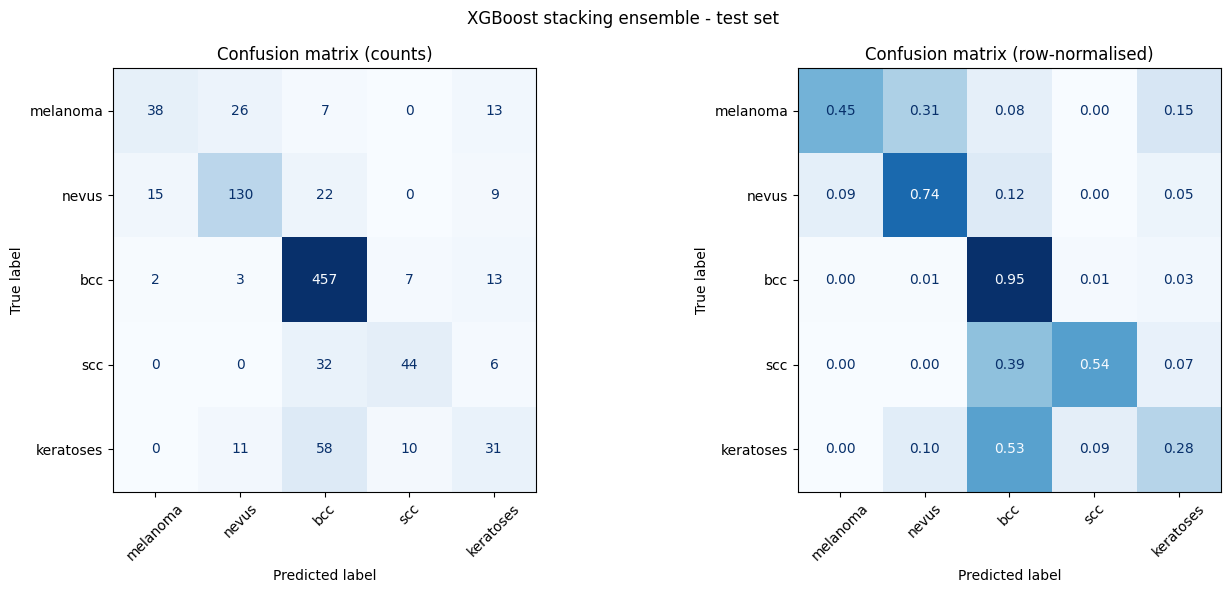

In [10]:
# %% ====================== CELL 8: Test probabilities + FINAL evaluation ==
# WHAT IT DOES: ONLY NOW is the test set passed through the three base models.
# XGBoost (already trained) predicts the final class. Test labels are used
# only to compute the metrics.
test_loader = make_loader(test_ds)
test_cache = os.path.join(SAVE_DIR, "test_probabilities.npz")
if REUSE_CACHED_FEATURES and os.path.exists(test_cache):
    d = np.load(test_cache, allow_pickle=True)
    assert np.array_equal(d["y"], y_test), "Cached test labels differ - delete the cache."
    test_probs = {n: d[n] for n in MODEL_NAMES}
    print("Loaded cached test probabilities.")
else:
    t0 = time.time()
    test_probs = extract_probs(test_loader, base_models)
    np.savez(test_cache, y=y_test, files=np.array([p for p, _ in test_ds.samples]), **test_probs)
    print(f"Test extraction took {time.time() - t0:.0f}s and was saved to Drive.")

X_test = stack_features(test_probs)
print("\nSanity checks (test)")
print("-" * 60)
for n in MODEL_NAMES:
    print(f"{n:12s} probability shape: {test_probs[n].shape}")
print("Stacked test feature shape:", X_test.shape, "(expected:", (len(test_ds), 15), ")")
assert X_test.shape == (len(test_ds), 15)

y_pred = xgb_meta.predict(X_test)
y_proba = xgb_meta.predict_proba(X_test)

def all_metrics(y_true, y_hat):
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_hat, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_hat, average="weighted", zero_division=0)
    return {"Accuracy": accuracy_score(y_true, y_hat),
            "Balanced Accuracy": balanced_accuracy_score(y_true, y_hat),
            "Macro Precision": pm, "Macro Recall": rm, "Macro F1": fm,
            "Weighted Precision": pw, "Weighted Recall": rw, "Weighted F1": fw}

results = {"XGBoost stacking": all_metrics(y_test, y_pred)}
for n in MODEL_NAMES:
    results[n + " (alone)"] = all_metrics(y_test, test_probs[n].argmax(1))
results["Mean-probability ensemble"] = all_metrics(
    y_test, sum(test_probs[n] for n in MODEL_NAMES).argmax(1))   # baseline, no training needed
results_df = pd.DataFrame(results).T

print("\n" + "=" * 70)
print("FINAL TEST RESULTS - XGBoost STACKING ENSEMBLE")
print("=" * 70)
for k, v in results["XGBoost stacking"].items():
    print(f"{k:20s}: {v:.4f}")

print("\nComparison on the test set (evaluation only, nothing tuned on it):")
print(results_df.round(4).to_string())

report_txt = classification_report(y_test, y_pred, labels=list(range(NUM_CLASSES)),
                                   target_names=TARGET_CLASSES, digits=4, zero_division=0)
print("\nPer-class classification report (XGBoost stacking):\n")
print(report_txt)

cm = confusion_matrix(y_test, y_pred, labels=list(range(NUM_CLASSES)))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ConfusionMatrixDisplay(cm, display_labels=TARGET_CLASSES).plot(
    ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=45)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=TARGET_CLASSES).plot(
    ax=axes[1], cmap="Blues", colorbar=False, xticks_rotation=45, values_format=".2f")
axes[1].set_title("Confusion matrix (row-normalised)")
plt.suptitle("XGBoost stacking ensemble - test set")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "confusion_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()

In [11]:
# %% ====================== CELL 9: Save everything to Drive ==============
# WHAT IT DOES: saves the XGBoost model, metrics, report, predictions and
# the settings needed to reproduce / reuse the pipeline.
xgb_meta.save_model(os.path.join(SAVE_DIR, "xgboost_meta_model.json"))

results_df.round(6).to_csv(os.path.join(SAVE_DIR, "test_metrics_comparison.csv"))
with open(os.path.join(SAVE_DIR, "classification_report.txt"), "w") as f:
    f.write("XGBoost stacking ensemble - test set\n\n")
    for k, v in results["XGBoost stacking"].items():
        f.write(f"{k:20s}: {v:.4f}\n")
    f.write("\n" + report_txt)

pd.DataFrame({
    "file": [p for p, _ in test_ds.samples],
    "true": [TARGET_CLASSES[i] for i in y_test],
    "predicted": [TARGET_CLASSES[i] for i in y_pred],
    **{f"p_{c}": y_proba[:, i] for i, c in enumerate(TARGET_CLASSES)},
}).to_csv(os.path.join(SAVE_DIR, "test_predictions.csv"), index=False)

with open(os.path.join(SAVE_DIR, "pipeline_config.json"), "w") as f:
    json.dump({
        "target_classes": TARGET_CLASSES,
        "model_class_order_used": MODEL_CLASS_ORDER_RESOLVED,
        "model_feature_order": MODEL_NAMES,
        "feature_names": FEATURE_NAMES,
        "img_size": IMG_SIZE, "mean": MEAN, "std": STD, "batch_size": BATCH_SIZE,
        "xgb_best_rounds": best_rounds, "xgb_params": {k: v for k, v in XGB_PARAMS.items()},
        "xgb_device": DEVICE_NAME, "class_weights": USE_CLASS_WEIGHTS, "seed": SEED,
        "val_samples": int(len(y_val)), "test_samples": int(len(y_test)),
    }, f, indent=2)

print("Saved to", SAVE_DIR)
for fn in sorted(os.listdir(SAVE_DIR)):
    print("  -", fn)

# To reload the meta-model later (no retraining needed):
#   m = xgb.XGBClassifier(); m.load_model(os.path.join(SAVE_DIR, "xgboost_meta_model.json"))
#   m.predict(X)      # X = 15 probability features in the order of FEATURE_NAMES



Saved to /content/drive/MyDrive/stacking_xgboost_results
  - classification_report.txt
  - confusion_matrix.png
  - gradcam_shap_results
  - pipeline_config.json
  - test_metrics_comparison.csv
  - test_predictions.csv
  - test_probabilities.npz
  - val_probabilities.npz
  - xgboost_meta_model.json


Device: cuda
Test image index: 0
Saving results to: /content/drive/MyDrive/stacking_xgboost_results/gradcam_shap_results
True class: scc

Generating Grad-CAM: resnet50


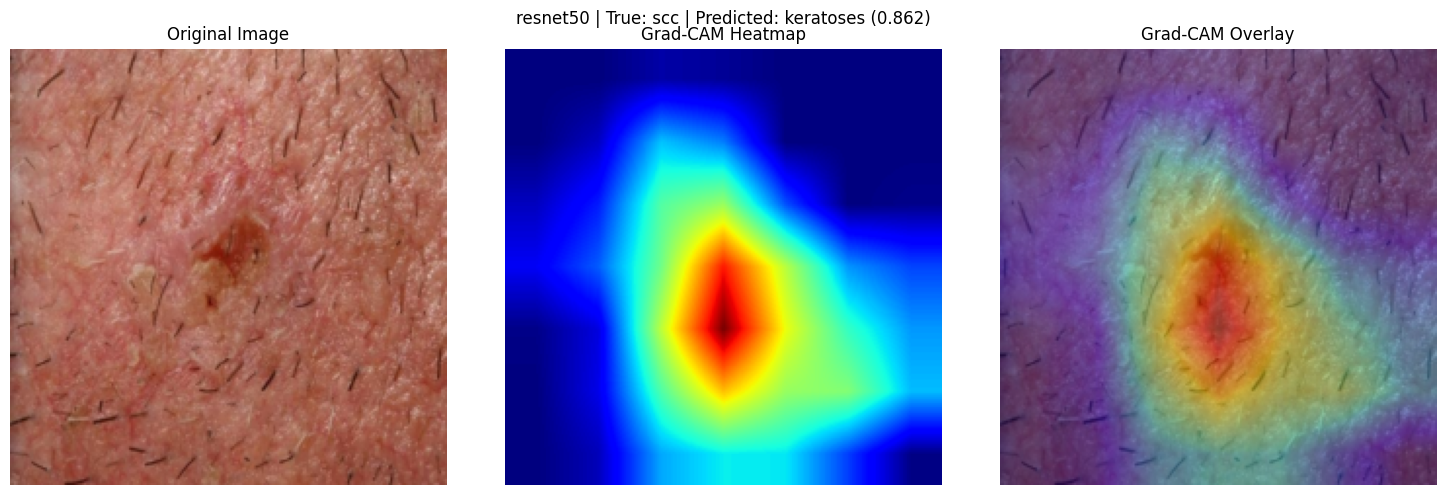

True class: scc
Predicted class: keratoses
Confidence: 0.862
Grad-CAM layer: layer4.2.conv3
Saved: /content/drive/MyDrive/stacking_xgboost_results/gradcam_shap_results/resnet50_gradcam_0.png

Generating Grad-CAM: inceptionv3


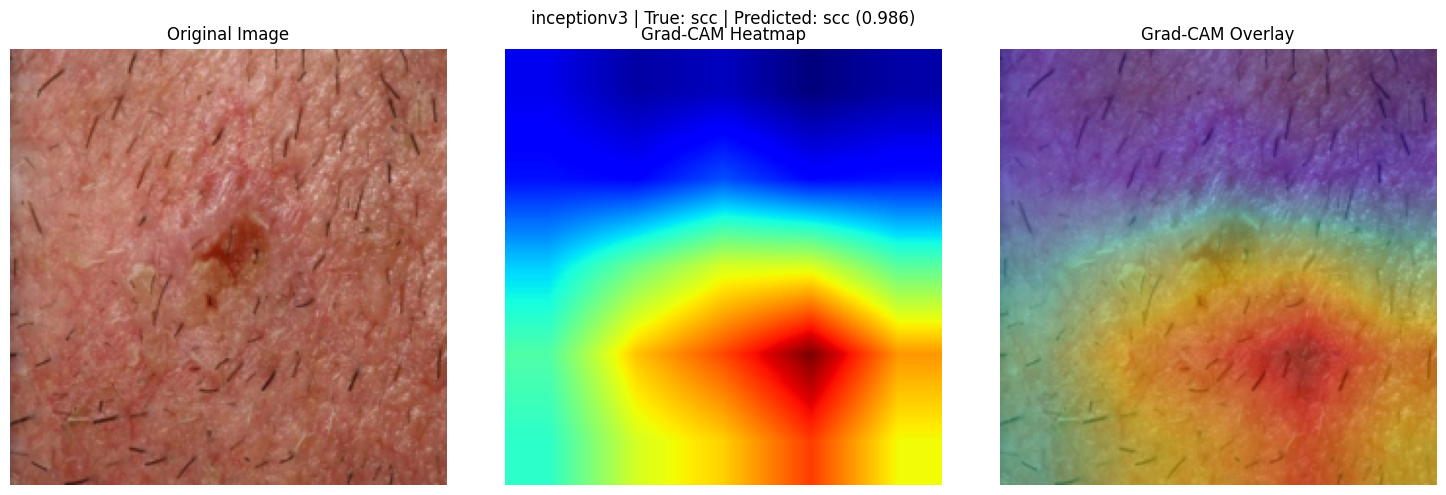

True class: scc
Predicted class: scc
Confidence: 0.9861
Grad-CAM layer: Mixed_7c.branch_pool.conv
Saved: /content/drive/MyDrive/stacking_xgboost_results/gradcam_shap_results/inceptionv3_gradcam_0.png

Generating Grad-CAM: ghostnetv2


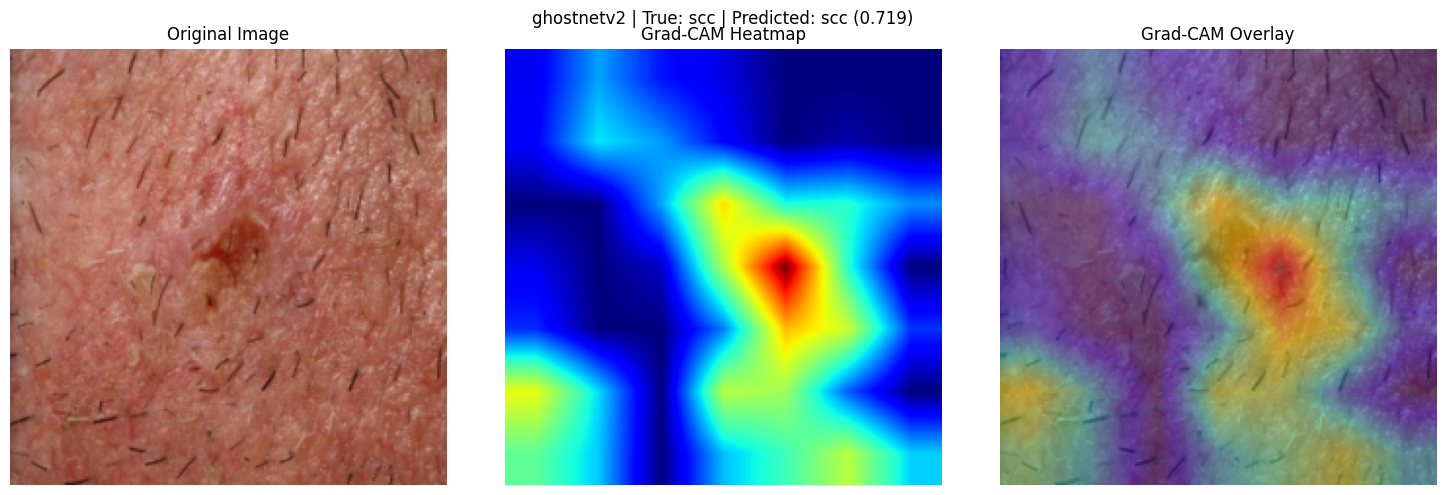

True class: scc
Predicted class: scc
Confidence: 0.7191
Grad-CAM layer: backbone.blocks.9.0.conv
Saved: /content/drive/MyDrive/stacking_xgboost_results/gradcam_shap_results/ghostnetv2_gradcam_0.png

Generating SHAP explanation for XGBoost...
True class: scc
XGBoost predicted class: scc
XGBoost confidence: 0.4614


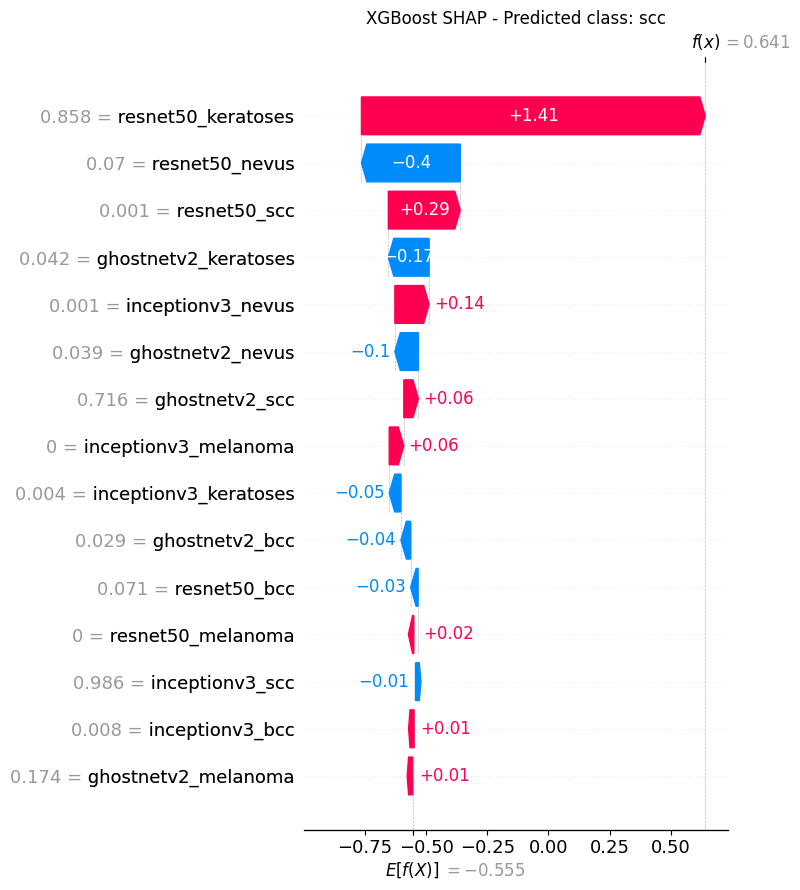


Top XGBoost features influencing this class:
              Feature  Input_Probability  SHAP_Value  Absolute_SHAP
   resnet50_keratoses           0.858364    1.405343       1.405343
       resnet50_nevus           0.069502   -0.403996       0.403996
         resnet50_scc           0.000601    0.294057       0.294057
 ghostnetv2_keratoses           0.041641   -0.166656       0.166656
    inceptionv3_nevus           0.001457    0.139953       0.139953
     ghostnetv2_nevus           0.039233   -0.096178       0.096178
       ghostnetv2_scc           0.716090    0.059647       0.059647
 inceptionv3_melanoma           0.000158    0.059525       0.059525
inceptionv3_keratoses           0.004324   -0.047735       0.047735
       ghostnetv2_bcc           0.028619   -0.039682       0.039682

All available outputs saved in: /content/drive/MyDrive/stacking_xgboost_results/gradcam_shap_results
SHAP plot: /content/drive/MyDrive/stacking_xgboost_results/gradcam_shap_results/xgboost_shap_0.png
SHAP 

In [12]:

# ============================================================
# GRAD-CAM FOR RESNET50, INCEPTIONV3, GHOSTNETV2
# + SHAP FOR XGBOOST STACKING ENSEMBLE
# NO RETRAINING
# ============================================================

import os
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])

import shap
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import torch.nn.functional as F

from PIL import Image

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

IMG_INDEX = 0
DEVICE_XAI = device
XAI_DIR = os.path.join(SAVE_DIR, "gradcam_shap_results")
os.makedirs(XAI_DIR, exist_ok=True)

assert IMG_INDEX < len(test_ds), "IMG_INDEX exceeds test dataset size."
assert isinstance(base_models, dict), "Expected base_models as a dictionary."
assert "xgb_meta" in globals(), "Run the XGBoost training cell first."
assert "X_test" in globals(), "Run the test feature extraction cell first."

print("Device:", DEVICE_XAI)
print("Test image index:", IMG_INDEX)
print("Saving results to:", XAI_DIR)

# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------

def get_logits(output):
    if isinstance(output, (tuple, list)):
        output = output[0]
    if hasattr(output, "logits"):
        output = output.logits
    if not torch.is_tensor(output):
        raise TypeError("Model output is not a tensor.")
    return output

def get_display_image(image_tensor):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    img = image_tensor.detach().cpu() * std + mean
    return img.clamp(0, 1).permute(1, 2, 0).numpy()

# Use the same test image for all models.
input_image, true_label = test_ds[IMG_INDEX]
input_batch = input_image.unsqueeze(0).to(DEVICE_XAI)
display_image = get_display_image(input_image)
true_class = TARGET_CLASSES[int(true_label)]

print("True class:", true_class)

# ------------------------------------------------------------
# GRAD-CAM FOR EACH CNN
# ------------------------------------------------------------

for model_name, model in base_models.items():

    print("\nGenerating Grad-CAM:", model_name)

    model = model.to(DEVICE_XAI)
    model.eval()

    activations = {}
    gradients = {}
    handles = []

    # Hook every convolution layer. Select the deepest layer
    # whose feature map still has spatial dimensions.
    conv_layers = [
        (name, module)
        for name, module in model.named_modules()
        if isinstance(module, nn.Conv2d)
    ]

    if not conv_layers:
        print("No Conv2d layer found. Skipping:", model_name)
        continue

    for layer_name, layer in conv_layers:

        def save_activation(module, inputs, output, name=layer_name):
            if torch.is_tensor(output):
                activations[name] = output
                if output.requires_grad:
                    output.register_hook(
                        lambda grad, n=name: gradients.__setitem__(
                            n, grad.detach()
                        )
                    )

        handles.append(
            layer.register_forward_hook(save_activation)
        )

    try:
        model.zero_grad(set_to_none=True)

        x = input_batch.detach().clone().requires_grad_(True)
        output = get_logits(model(x))

        if output.ndim != 2 or output.shape[1] != len(TARGET_CLASSES):
            raise ValueError(
                f"{model_name} returned shape {tuple(output.shape)}; "
                "expected [batch, 5]."
            )

        probabilities = torch.softmax(output.detach(), dim=1)
        predicted_index = int(probabilities[0].argmax().item())
        predicted_class = MODEL_CLASS_ORDER_RESOLVED[predicted_index]
        confidence = float(probabilities[0, predicted_index].item())

        # Find deepest convolution with a spatial feature map.
        valid_layers = [
            name for name, activation in activations.items()
            if activation.ndim == 4
            and activation.shape[-2] > 1
            and activation.shape[-1] > 1
        ]

        if not valid_layers:
            raise RuntimeError("No suitable spatial feature map found.")

        target_layer_name = valid_layers[-1]
        target_activation = activations[target_layer_name]

        model.zero_grad(set_to_none=True)
        output[0, predicted_index].backward()

        if target_layer_name not in gradients:
            raise RuntimeError(
                "Gradients were not captured for the selected layer."
            )

        activation = target_activation.detach()
        gradient = gradients[target_layer_name]

        weights = gradient.mean(dim=(2, 3), keepdim=True)
        cam = (weights * activation).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=(input_image.shape[1], input_image.shape[2]),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min())
        else:
            cam = np.zeros_like(cam)

        # Visualize and save.
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        axes[0].imshow(display_image)
        axes[0].set_title("Original Image")

        axes[1].imshow(cam, cmap="jet", vmin=0, vmax=1)
        axes[1].set_title("Grad-CAM Heatmap")

        axes[2].imshow(display_image)
        axes[2].imshow(cam, cmap="jet", alpha=0.40, vmin=0, vmax=1)
        axes[2].set_title("Grad-CAM Overlay")

        for ax in axes:
            ax.axis("off")

        fig.suptitle(
            f"{model_name} | True: {true_class} | "
            f"Predicted: {predicted_class} ({confidence:.3f})"
        )
        plt.tight_layout()

        save_path = os.path.join(
            XAI_DIR, f"{model_name}_gradcam_{IMG_INDEX}.png"
        )
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        print("True class:", true_class)
        print("Predicted class:", predicted_class)
        print("Confidence:", round(confidence, 4))
        print("Grad-CAM layer:", target_layer_name)
        print("Saved:", save_path)

    except Exception as e:
        print("Grad-CAM failed for", model_name, ":", repr(e))

    finally:
        for handle in handles:
            handle.remove()

        model.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# SHAP FOR THE XGBOOST STACKING MODEL
# Explains the 15 probability features from the 3 CNNs.
# ------------------------------------------------------------

print("\nGenerating SHAP explanation for XGBoost...")

xgb_sample = np.asarray(X_test[IMG_INDEX:IMG_INDEX + 1], dtype=np.float32)

if xgb_sample.shape[1] != len(FEATURE_NAMES):
    raise ValueError(
        f"Expected {len(FEATURE_NAMES)} features, "
        f"got {xgb_sample.shape[1]}."
    )

xgb_prediction = int(xgb_meta.predict(xgb_sample)[0])
xgb_probabilities = xgb_meta.predict_proba(xgb_sample)[0]
xgb_predicted_class = TARGET_CLASSES[xgb_prediction]

print("True class:", true_class)
print("XGBoost predicted class:", xgb_predicted_class)
print("XGBoost confidence:", round(float(xgb_probabilities[xgb_prediction]), 4))

explainer = shap.TreeExplainer(xgb_meta)
shap_values = explainer.shap_values(xgb_sample)

# Handle SHAP return formats across versions.
if isinstance(shap_values, list):
    class_shap = np.asarray(shap_values[xgb_prediction]).reshape(-1)
else:
    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:
        # Common formats: (samples, features, classes)
        # or (classes, samples, features).
        if shap_array.shape[0] == 1:
            class_shap = shap_array[0, :, xgb_prediction]
        elif shap_array.shape[1] == 1:
            class_shap = shap_array[xgb_prediction, 0, :]
        else:
            raise ValueError(
                f"Unrecognized SHAP array shape: {shap_array.shape}"
            )
    elif shap_array.ndim == 2:
        class_shap = shap_array[0]
    else:
        raise ValueError(
            f"Unrecognized SHAP output shape: {shap_array.shape}"
        )

class_shap = np.asarray(class_shap).reshape(-1)

# Waterfall plot for this one sample and its predicted class.
base_values = np.asarray(explainer.expected_value)
if base_values.ndim == 0:
    base_value = float(base_values)
else:
    base_value = float(base_values.reshape(-1)[xgb_prediction])

explanation = shap.Explanation(
    values=class_shap,
    base_values=base_value,
    data=xgb_sample[0],
    feature_names=FEATURE_NAMES
)

plt.figure(figsize=(12, 7))
shap.plots.waterfall(explanation, max_display=15, show=False)
plt.title(f"XGBoost SHAP - Predicted class: {xgb_predicted_class}")
plt.tight_layout()

shap_path = os.path.join(
    XAI_DIR, f"xgboost_shap_{IMG_INDEX}.png"
)
plt.savefig(shap_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Save feature contributions as CSV.
shap_df = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Input_Probability": xgb_sample[0],
    "SHAP_Value": class_shap,
    "Absolute_SHAP": np.abs(class_shap)
}).sort_values("Absolute_SHAP", ascending=False)

csv_path = os.path.join(
    XAI_DIR, f"xgboost_shap_values_{IMG_INDEX}.csv"
)
shap_df.to_csv(csv_path, index=False)

print("\nTop XGBoost features influencing this class:")
print(shap_df.head(10).to_string(index=False))

print("\nAll available outputs saved in:", XAI_DIR)
print("SHAP plot:", shap_path)
print("SHAP values CSV:", csv_path)
